In [2]:
import sys
!{sys.executable} -m pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 940.5/940.5 kB 1.3 MB/s eta 0:00:00a 0:00:01


─── VALIDACIJA (Mesečni nivo: Jun 2024 – Jun 2025) ─────
      Date  Realizovana_Stvarna_Vol  GARCH_Vol_Monthly
2024-06-01                     3.82           1.979771
2024-07-01                     6.44           1.979771
2024-08-01                     5.75           1.995942
2024-09-01                     4.95           1.985006
2024-10-01                     7.21           1.973010
2024-11-01                     5.50           1.982450
2024-12-01                     5.59           1.959932
2025-01-01                     9.99           1.922328
2025-02-01                     4.33           1.894191
2025-03-01                     7.29           1.894538
2025-04-01                    13.50           1.909226
2025-05-01                     4.73           1.882189
2025-06-01                     3.03           2.013669


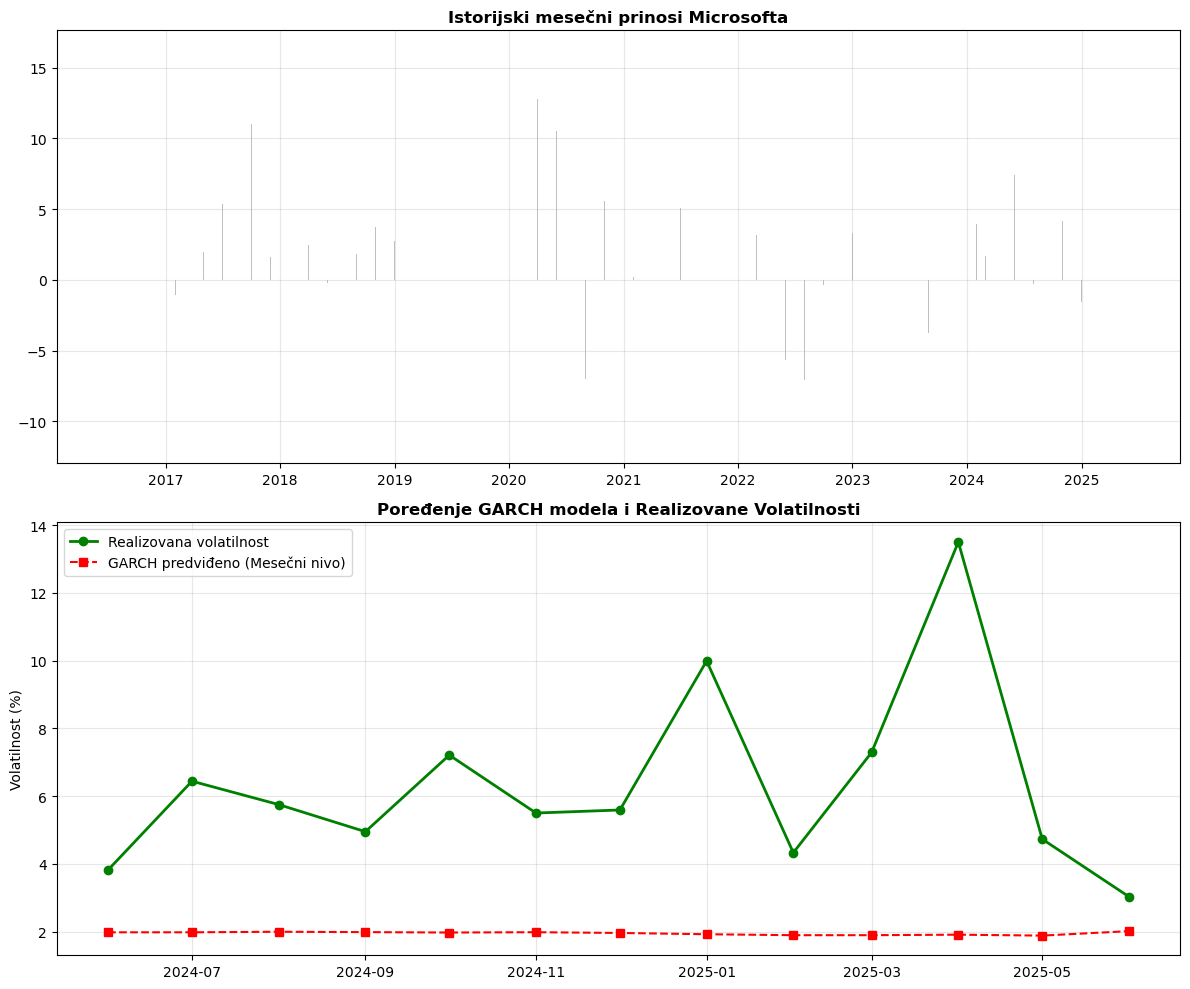

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -334.413
Distribution:                  Normal   AIC:                           676.827
Method:            Maximum Likelihood   BIC:                           687.518
                                        No. Observations:                  107
Date:                Sat, May 30 2026   Df Residuals:                      106
Time:                        18:20:13   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             2.2292      0.523      4.263  2.017e-05 [  1.204,  3.25

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model

# ── UČITAVANJE PODATAKA ─────────────────────────────────────
df = pd.read_csv('/Users/tamaradrca/Podaci za diplomski/Microsoft Stock Price History.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)
df['Price'] = df['Price'].astype(str).str.replace(',', '').astype(float)
df = df[['Date', 'Price']].dropna().drop_duplicates(subset=['Date'])

# Prinos u % (Logaritamski prinosi su stabilniji za GARCH)
df['Return'] = 100 * np.log(df['Price'] / df['Price'].shift(1))
df = df.dropna().reset_index(drop=True)

# ── 1. PODELA PODATAKA ──────────────────────────────────────
train = df[df['Date'] <= '2024-06-01'].copy()
test  = df[(df['Date'] >= '2024-06-01') & (df['Date'] <= '2025-06-01')].copy()

# ── 2. TVOJI STVARNI REZULTATI (Realizovana vol iz dnevnih) ──
# Redosled prati mesece u test setu: Jun 2024 -> Jun 2025
stvarne_vrednosti = [3.82, 6.44, 5.75, 4.95, 7.21, 5.50, 5.59, 9.99, 4.33, 7.29, 13.50, 4.73, 3.03]

# ── 3. ROLLING FORECAST ZA TEST SET ────────────────────────
pred_vols_annual = []
for i in range(len(test)):
    cutoff = test['Date'].iloc[i - 1] if i > 0 else pd.Timestamp('2024-06-01')
    train_expanded = df[df['Date'] <= cutoff].copy()
    
    m  = arch_model(train_expanded['Return'], vol='Garch', p=1, q=1, dist='normal')
    mf = m.fit(disp='off')
    fc = mf.forecast(horizon=1)
    
    # GARCH daje godišnju varijansu, vadimo koren za godišnju volatilnost
    vol_annual = np.sqrt(fc.variance.values[-1, 0])
    pred_vols_annual.append(vol_annual)

test = test.copy()

# DODATA PROMENA: Delimo sa koren iz 12 da dobijemo mesečni nivo
test['GARCH_Vol_Monthly'] = np.array(pred_vols_annual) / np.sqrt(12)

# UBACIVANJE STVARNIH REZULTATA
test['Realizovana_Stvarna_Vol'] = stvarne_vrednosti

print("─── VALIDACIJA (Mesečni nivo: Jun 2024 – Jun 2025) ─────")
print(test[['Date', 'Realizovana_Stvarna_Vol', 'GARCH_Vol_Monthly']].to_string(index=False))





# ── 5. VIZUALIZACIJA ────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Graf 1: Prinosi
axes[0].bar(df['Date'], df['Return'], color='gray', alpha=0.5)
axes[0].set_title('Istorijski mesečni prinosi Microsofta', fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Graf 2: Validacija (Sada poredimo "babe sa babama")
axes[1].plot(test['Date'], test['Realizovana_Stvarna_Vol'], 
             marker='o', linewidth=2, label='Realizovana volatilnost', color='green')
axes[1].plot(test['Date'], test['GARCH_Vol_Monthly'], 
             marker='s', linestyle='--', label='GARCH predviđeno (Mesečni nivo)', color='red')



axes[1].set_title('Poređenje GARCH modela i Realizovane Volatilnosti', fontweight='bold')
axes[1].set_ylabel('Volatilnost (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(mf.summary())